# The CA1 population for the place-cell fit (Sec. 3.2, App. K)

Builds the CA1 rate maps behind the place-cell fit and shows the population before and after
each selection step, so that the choice of units is visible.

**Data.** The open-field CA1 recordings of Blackstad, Moser and Moser (2024), published with
Carpenter et al. (2024): five rats foraging in a 150 × 150 cm arena, tetrodes in dorsal CA1,
clusters cut with MClust. `data/ca1_events.npz` contains the tracking and spike times of the
whole release, extracted by `experimental_data/extract_ca1.py`, and `experimental_data/ca1.py`
documents the format and builds the rate maps.

**Selection.** The release contains 2729 cluster files, the source paper counts 1002 units, and
the curated list is not part of the release. Three steps go from the cluster files to the
selected population.

1. _Duplicates._ A cluster nested in a larger cluster of the same session, sharing more than
   half its spikes with it, is treated as a duplicate and dropped.
2. _Mean rate._ A unit is kept if its mean rate over the session lies between 1 and 10 Hz, the
   criterion of the source paper.
3. _Spatial information._ The model describes how the rate of a unit depends on position, so a
   unit whose rate carries little information about position gives the fit nothing to work
   with. Units below 0.5 bits per spike are dropped. This criterion is ours, not the source
   paper's, and the dropped units stay in the gallery below so that the cut is visible.

**Preprocessing** follows the source paper: head position smoothed with a Gaussian of 3
samples, frames outside 6 to 60 cm/s discarded, 32 bins across the occupied extent (about
4.3 cm per bin). Rate maps are indexed `(unit, bins_x, bins_y)` like `data/gc_ratmaps.npy` and
are shown in arena coordinates.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "notebooks" / "experimental_data"))
from ca1 import (  # noqa: E402
    border_score,
    load_events,
    place_fields,
    population_ratemaps,
    select_units,
    split_half_correlation,
)

EVENTS = REPO_ROOT / "data" / "ca1_events.npz"
OUTPUT = REPO_ROOT / "data" / "ca1_ratemaps.npz"
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

# RATE_RANGE is the source paper's criterion, INFO_THRESHOLD ours.
RATE_RANGE = (1.0, 10.0)  # Hz, mean over the session
INFO_THRESHOLD = 0.5  # bits per spike, Skaggs spatial information
N_BINS = 32
MAP_SIGMA = 1.0  # bins, smoothing of spike counts and occupancy before dividing
POSITION_SIGMA = 3.0  # samples
SPEED_RANGE = (6.0, 60.0)  # cm/s

# Field metrics, computed for every unit and stored with the rate maps. The candidate rule is
# reported for its count and not applied; the fit takes every spatially tuned unit of one rat.
FIELD_THRESHOLD = 0.2  # of peak rate, for delineating fields
FIELD_MIN_BINS = 9  # ~170 cm^2 at 4.3 cm bins
CANDIDATE_RULE = {"max_fields": 1, "max_border": 0.5, "min_stability": 0.5}

## Counts at each step


In [2]:
sessions, units = load_events(EVENTS)
animals = sorted({s.animal for s in sessions})

not_duplicate = np.array([i for i, u in enumerate(units) if u.duplicate_of < 0])
rate_passing = select_units(units, RATE_RANGE)


def per_animal(indices):
    return {a: int(sum(sessions[units[i].session].animal == a for i in indices)) for a in animals}


print(f"{len(sessions)} sessions, {len(units)} cluster files")
print(f"{len(not_duplicate):5d} after dropping nested duplicates   {per_animal(not_duplicate)}")
print(f"{len(rate_passing):5d} with mean rate in {RATE_RANGE} Hz     {per_animal(rate_passing)}")

rates, occupancy, information = population_ratemaps(
    sessions, units, rate_passing, N_BINS, MAP_SIGMA, POSITION_SIGMA, SPEED_RANGE
)
selected = rate_passing[information >= INFO_THRESHOLD]
print(f"{len(selected):5d} with spatial information >= {INFO_THRESHOLD} bits/spike   {per_animal(selected)}")

114 sessions, 2729 cluster files
 2086 after dropping nested duplicates   {'24101': 367, '24116': 272, '25398': 703, '26019': 366, '26191': 378}
  425 with mean rate in (1.0, 10.0) Hz     {'24101': 98, '24116': 19, '25398': 151, '26019': 68, '26191': 89}


  223 with spatial information >= 0.5 bits/spike   {'24101': 50, '24116': 12, '25398': 107, '26019': 24, '26191': 30}


## Mean rate and spatial information


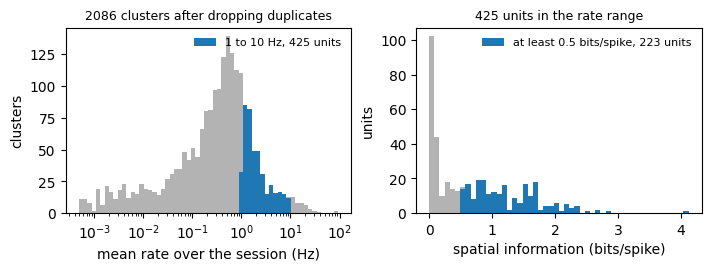

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(7, 2.6), layout="constrained")

all_rates = np.array([units[i].mean_rate for i in not_duplicate])
all_rates = all_rates[all_rates > 0]
rate_bins = np.logspace(np.log10(all_rates.min()), np.log10(all_rates.max()), 61)
in_range = (all_rates >= RATE_RANGE[0]) & (all_rates <= RATE_RANGE[1])
axs[0].hist(all_rates, bins=rate_bins, color="0.7")
axs[0].hist(all_rates[in_range], bins=rate_bins, color="C0", label=f"{RATE_RANGE[0]:g} to {RATE_RANGE[1]:g} Hz, {in_range.sum()} units")
axs[0].set_xscale("log")
axs[0].set_xlabel("mean rate over the session (Hz)")
axs[0].set_ylabel("clusters")
axs[0].set_title(f"{len(not_duplicate)} clusters after dropping duplicates", fontsize=9)
axs[0].legend(frameon=False, fontsize=8)

info_bins = np.linspace(0, information.max(), 51)
above = information >= INFO_THRESHOLD
axs[1].hist(information, bins=info_bins, color="0.7")
axs[1].hist(information[above], bins=info_bins, color="C0", label=f"at least {INFO_THRESHOLD} bits/spike, {above.sum()} units")
axs[1].set_xlabel("spatial information (bits/spike)")
axs[1].set_ylabel("units")
axs[1].set_title(f"{len(rate_passing)} units in the rate range", fontsize=9)
axs[1].legend(frameon=False, fontsize=8)
fig.savefig(FIGURE_DIR / "ca1_selection_histograms.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_selection_histograms.png", dpi=200, bbox_inches="tight")

## All units in the rate range, sorted by spatial information

Every unit that passes the mean-rate criterion, highest spatial information first. Panels below
the information threshold are framed in red. Each map is scaled to its own peak, so the panels
compare field shape and not amplitude, and the title gives the animal, the peak rate and the
spatial information.


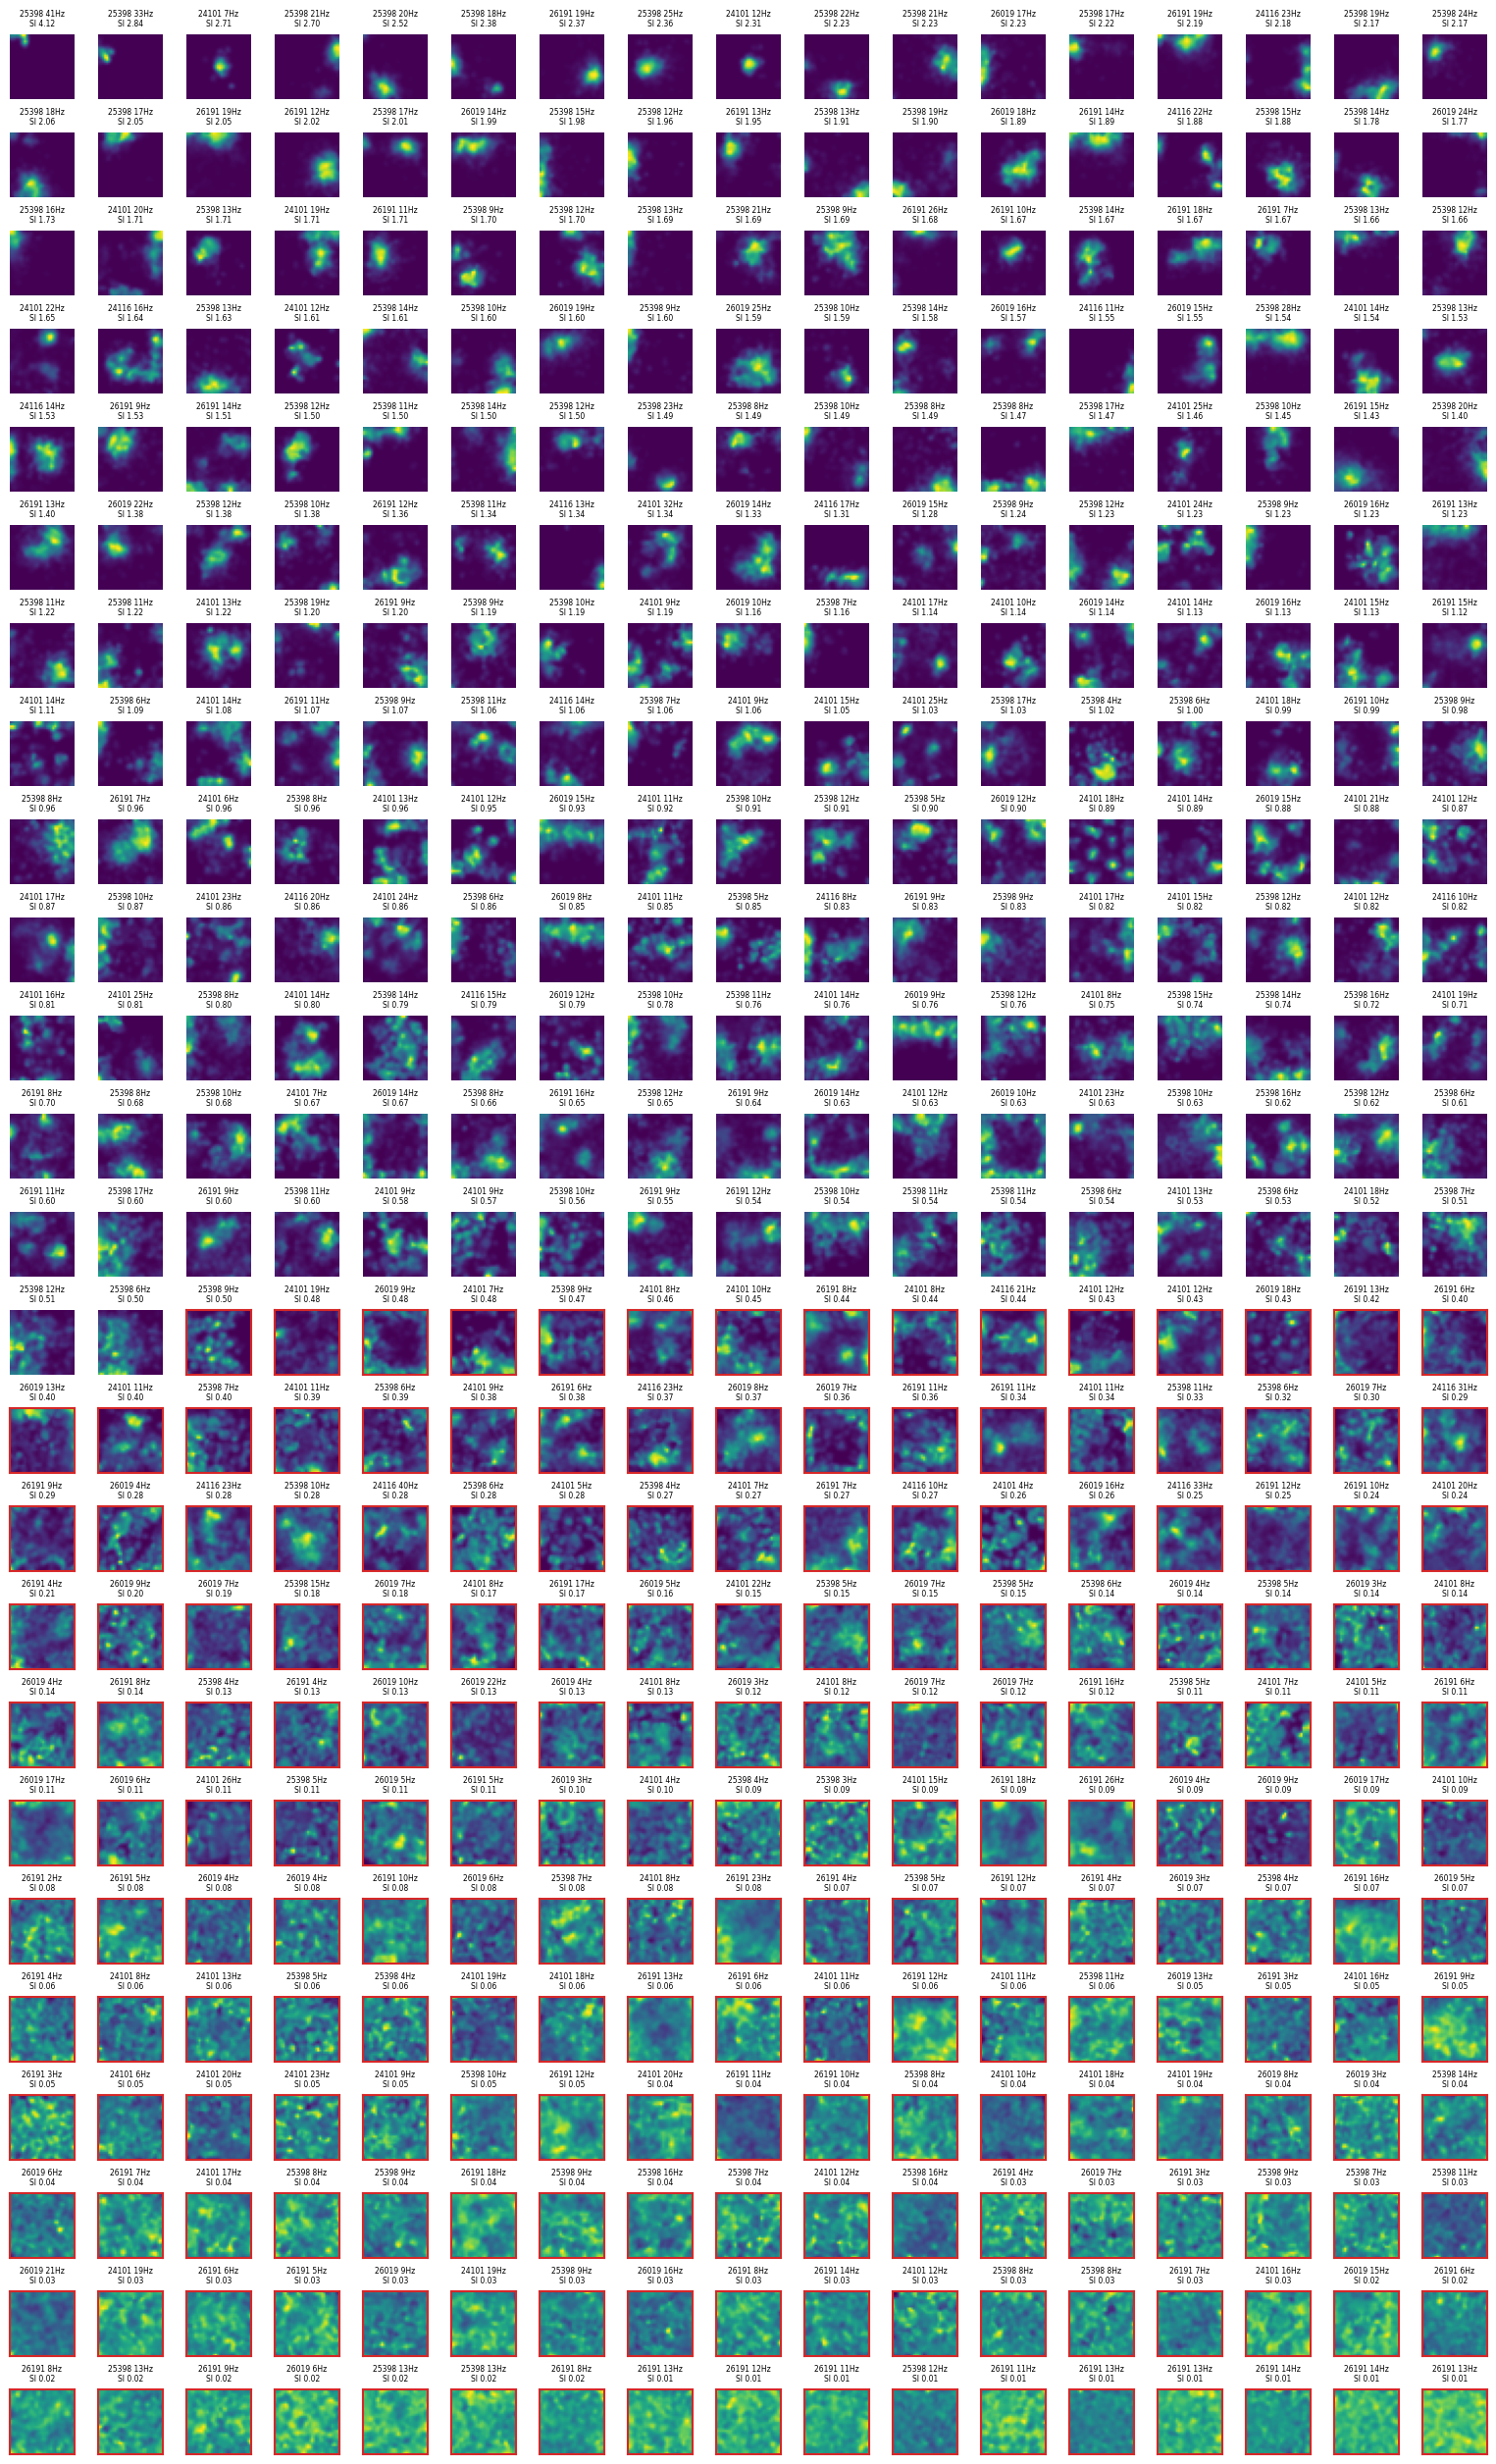

In [4]:
order = np.argsort(-information)
n_cols = 17
n_rows = int(np.ceil(len(order) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9, n_rows * 1.0), layout="constrained")
for ax in axs.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_visible(False)
for ax, k in zip(axs.ravel(), order):
    ax.set_visible(True)
    m = rates[k]
    ax.imshow(m.T / np.nanmax(m), origin="lower", cmap="viridis", vmin=0, vmax=1)
    u = units[rate_passing[k]]
    is_selected = information[k] >= INFO_THRESHOLD
    ax.set_title(f"{sessions[u.session].animal} {np.nanmax(m):.0f}Hz\nSI {information[k]:.2f}", fontsize=5.5)
    for spine in ax.spines.values():
        spine.set_edgecolor("none" if is_selected else "C3")
        spine.set_linewidth(1.5)
fig.savefig(FIGURE_DIR / "ca1_units_by_information.png", dpi=150, bbox_inches="tight")

## The selected population

The units that pass the information threshold, in the same order, on one color scale. The
scale is clipped at the 95th percentile of the peak rates, since three units above 30 Hz would
otherwise leave a typical 13 Hz unit faint. Panels that saturate are the ones above that
percentile.


223 units, peak rates 3.7..40.6 Hz, median 12.7, scale clipped at 24.1 Hz


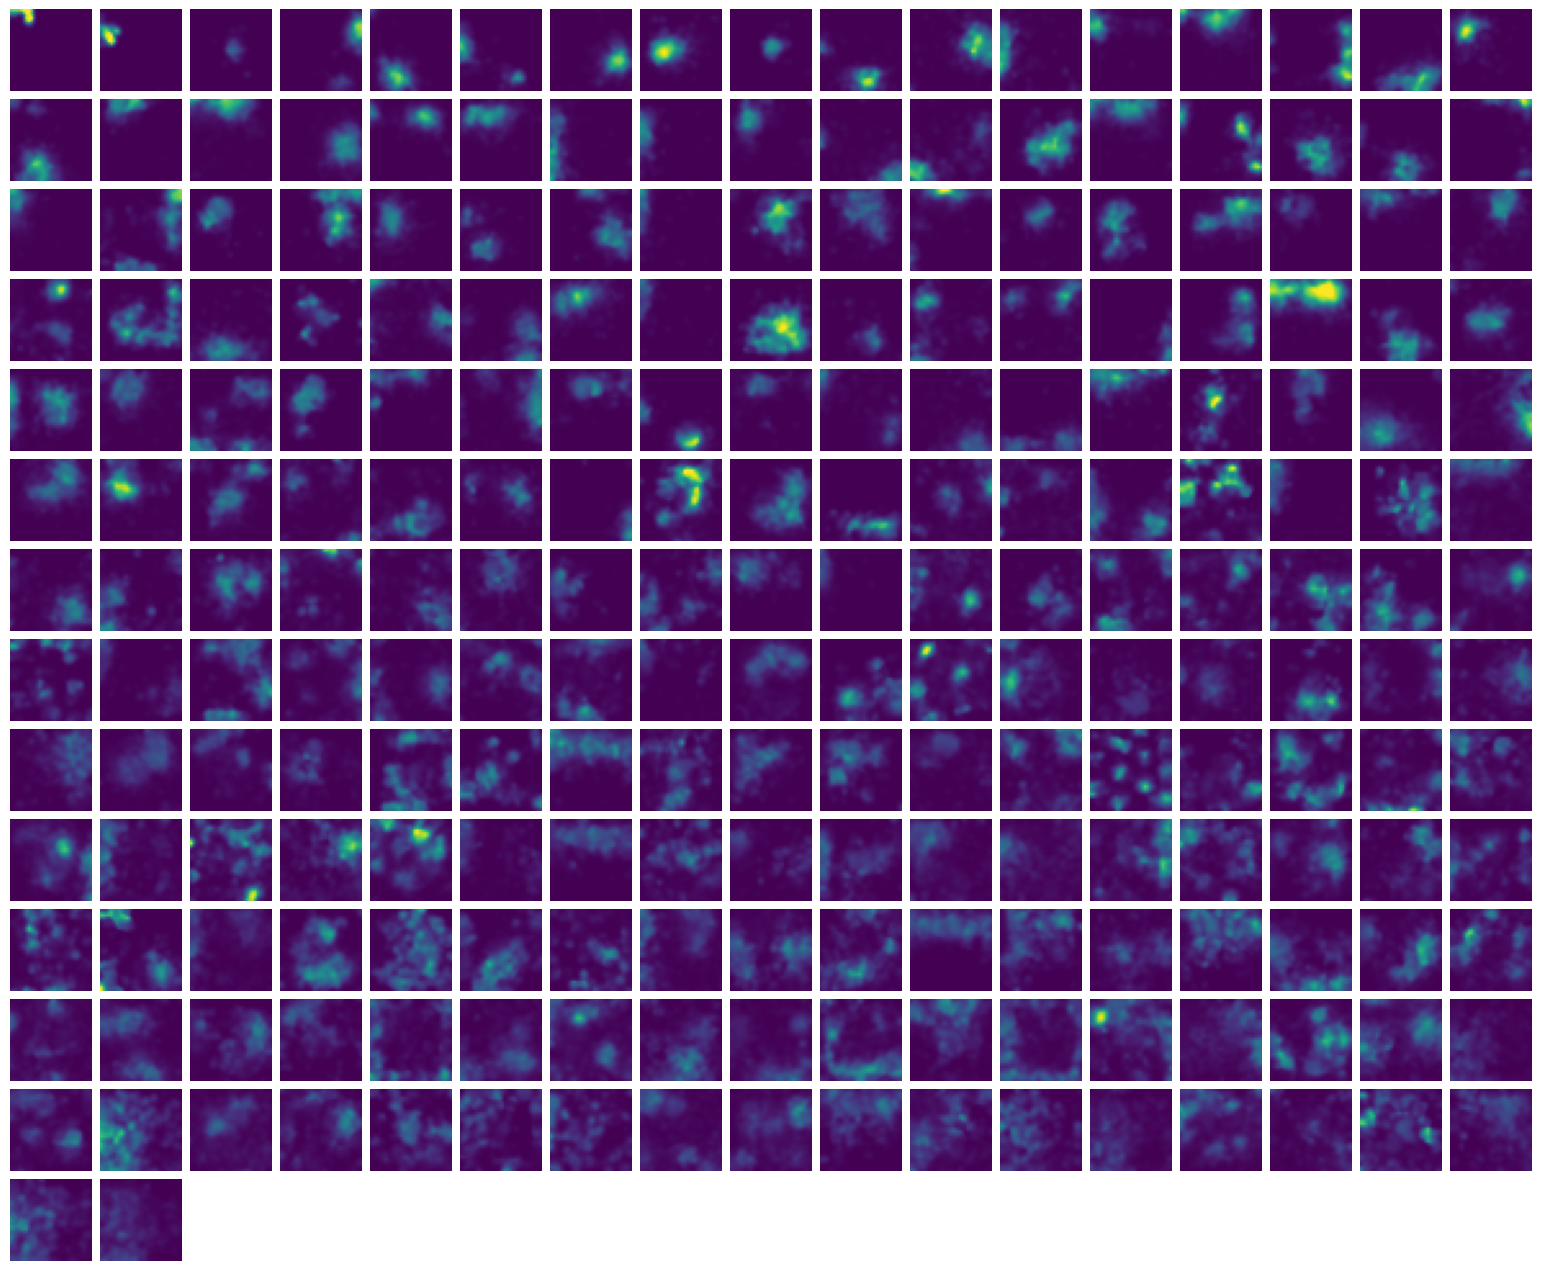

In [5]:
ranked = order[information[order] >= INFO_THRESHOLD]  # indices into rate_passing, highest information first
n_cols = 17
n_rows = int(np.ceil(len(ranked) / n_cols))
peaks = np.nanmax(rates[ranked], axis=(1, 2))
vmax = np.percentile(peaks, 95)
fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9, n_rows * 0.9), layout="constrained")
for ax in axs.ravel():
    ax.axis("off")
for ax, k in zip(axs.ravel(), ranked):
    ax.imshow(rates[k].T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
fig.savefig(FIGURE_DIR / "ca1_selected_units.png", dpi=150, bbox_inches="tight")
print(f"{len(ranked)} units, peak rates {peaks.min():.1f}..{peaks.max():.1f} Hz, median {np.median(peaks):.1f}, scale clipped at {vmax:.1f} Hz")

## Fields, border tuning and stability

The information threshold admits border-like and multi-field units alongside single-field place
cells. Three metrics describe each selected unit:

- **Number of fields.** Contiguous regions above 20 % of the peak rate that cover at least
  9 bins, about 170 cm².
- **Border score** (Solstad et al. 2008), $b = (c_M - d_M)/(c_M + d_M)$, where $c_M$ is the
  largest fraction of any wall covered by a field and $d_M$ the rate-weighted mean distance of
  the field bins from the nearest wall, in units of half the arena side. A field along a whole
  wall scores 1 and a field in the center −1. Border cells conventionally score above 0.5.
- **Split-half stability.** Pearson correlation between the rate maps of the two halves of the
  session, over the bins visited in both.

The metrics are stored with the rate maps. A candidate rule for single-field place cells, one
field with a border score of at most 0.5 and a stability of at least 0.5, is counted below and
not applied: the place-cell fit of the paper (`fit_place_cells`) takes every spatially tuned
unit of one rat and sets no field criterion.


number of fields among the selected units: {1: 97, 2: 64, 3: 42, 4: 13, 5: 6, 10: 1}
border score > 0.5: 50
split-half correlation < 0.5: 11


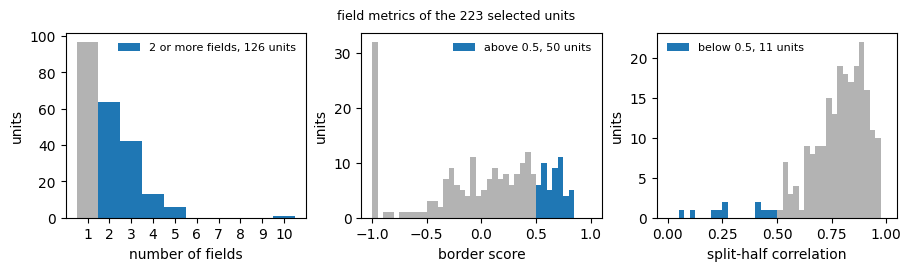

In [6]:
fields = [place_fields(r, FIELD_THRESHOLD, FIELD_MIN_BINS) for r in rates]
n_fields = np.array([f.max() for f in fields])
border = np.array([border_score(r, f) for r, f in zip(rates, fields)])
stability = split_half_correlation(sessions, units, rate_passing, N_BINS, MAP_SIGMA, POSITION_SIGMA, SPEED_RANGE)

selected_mask = information >= INFO_THRESHOLD
counts = {int(n): int((n_fields[selected_mask] == n).sum()) for n in np.unique(n_fields[selected_mask])}
print("number of fields among the selected units:", counts)
print(f"border score > {CANDIDATE_RULE['max_border']}: {int((border[selected_mask] > CANDIDATE_RULE['max_border']).sum())}")
print(f"split-half correlation < {CANDIDATE_RULE['min_stability']}: {int((stability[selected_mask] < CANDIDATE_RULE['min_stability']).sum())}")


def flagged_histogram(ax, values, flagged, bins, label, loc):
    values, flagged = values[np.isfinite(values)], flagged[np.isfinite(values)]
    ax.hist(values, bins=bins, color="0.7")
    ax.hist(values[flagged], bins=bins, color="C0", label=f"{label}, {flagged.sum()} units")
    ax.set_ylabel("units")
    ax.legend(frameon=False, fontsize=8, loc=loc)


fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), layout="constrained")
max_fields = n_fields[selected_mask].max()
flagged_histogram(
    axs[0],
    n_fields[selected_mask],
    n_fields[selected_mask] > CANDIDATE_RULE["max_fields"],
    np.arange(0.5, max_fields + 1.5),
    "2 or more fields",
    "upper right",
)
axs[0].set_xticks(np.arange(1, max_fields + 1))
axs[0].set_xlabel("number of fields")
flagged_histogram(
    axs[1],
    border[selected_mask],
    border[selected_mask] > CANDIDATE_RULE["max_border"],
    np.linspace(-1, 1, 41),
    f"above {CANDIDATE_RULE['max_border']}",
    "upper right",
)
axs[1].set_xlabel("border score")
flagged_histogram(
    axs[2],
    stability[selected_mask],
    stability[selected_mask] < CANDIDATE_RULE["min_stability"],
    np.linspace(0, 1, 41),
    f"below {CANDIDATE_RULE['min_stability']}",
    "upper left",
)
axs[2].set_xlabel("split-half correlation")
fig.suptitle(f"field metrics of the {selected_mask.sum()} selected units", fontsize=9)
fig.savefig(FIGURE_DIR / "ca1_field_metrics.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_field_metrics.png", dpi=200, bbox_inches="tight")

### Selected units by category

Every selected unit, each map at its own peak, with its fields outlined in white. The title of
a panel gives the number of fields (f), the border score (b) and the split-half correlation (s).
The categories are exclusive, assigned in this order: border-like (score above 0.5), unstable
(split-half correlation below 0.5), multi-field, single-field.


candidate rule {'max_fields': 1, 'max_border': 0.5, 'min_stability': 0.5}: 71 units   {'24101': 9, '24116': 3, '25398': 34, '26019': 11, '26191': 14}
single field, no border or stability criterion: 97 units, of which stable: 94
  with up to 2 fields: 116 units
  with up to 3 fields: 149 units


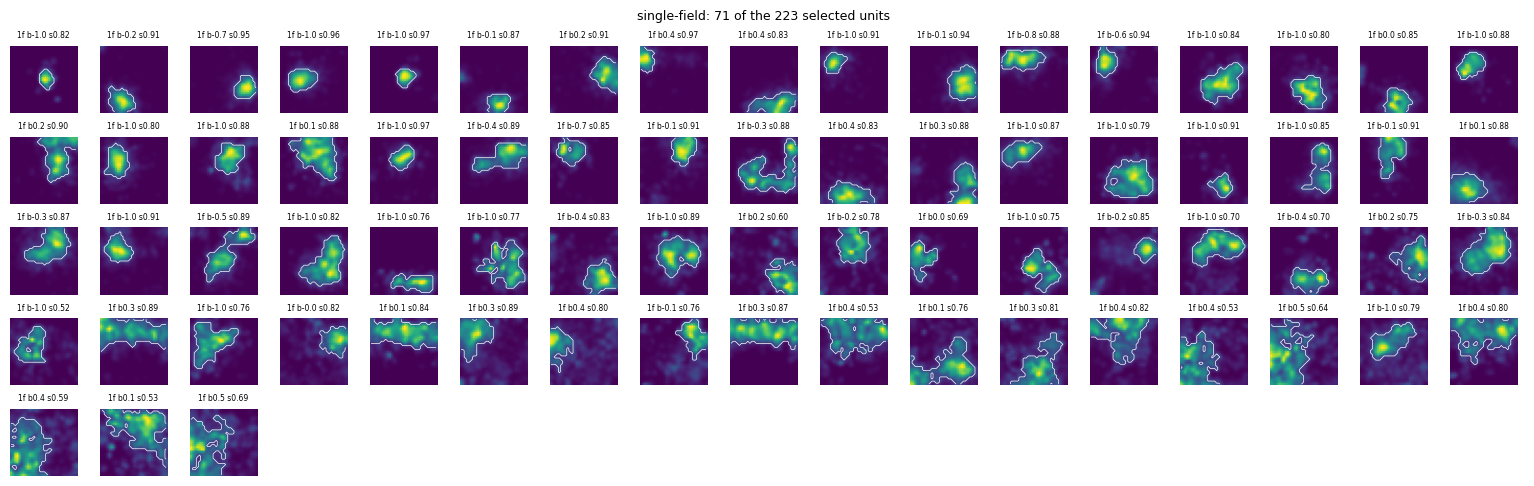

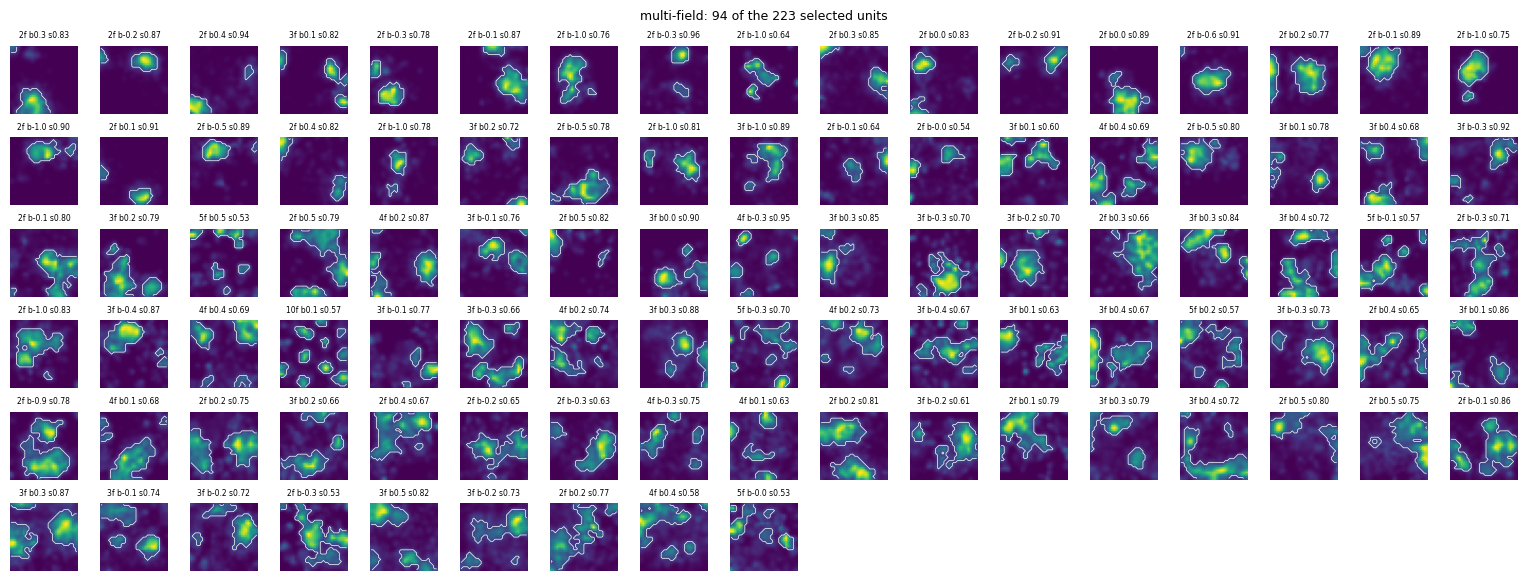

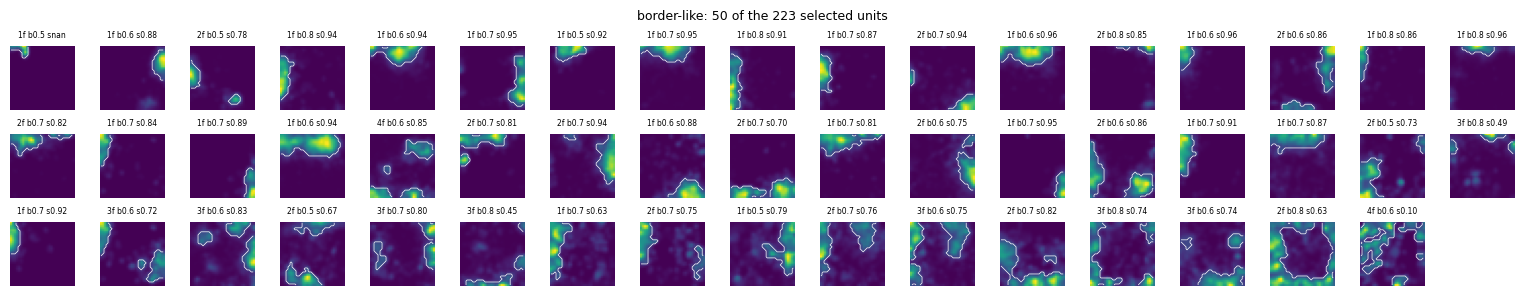

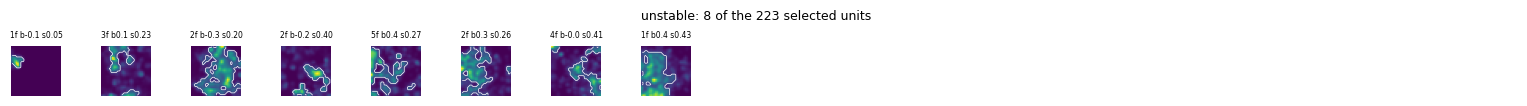

In [7]:
category = np.full(len(rate_passing), "single-field", dtype=object)
category[n_fields >= 2] = "multi-field"
category[~(stability >= CANDIDATE_RULE["min_stability"])] = "unstable"
category[border > CANDIDATE_RULE["max_border"]] = "border-like"
category[n_fields == 0] = "no field"

for name in ["single-field", "multi-field", "border-like", "unstable", "no field"]:
    members = ranked[category[ranked] == name]
    if len(members) == 0:
        continue
    n_cols = 17
    n_rows = int(np.ceil(len(members) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9, n_rows * 0.95), layout="constrained")
    for ax in np.atleast_1d(axs).ravel():
        ax.axis("off")
    for ax, k in zip(np.atleast_1d(axs).ravel(), members):
        ax.imshow(rates[k].T / np.nanmax(rates[k]), origin="lower", cmap="viridis", vmin=0, vmax=1)
        ax.contour(fields[k].T > 0, levels=[0.5], colors="w", linewidths=0.5)
        ax.set_title(f"{n_fields[k]}f b{border[k]:.1f} s{stability[k]:.2f}", fontsize=5.5)
    fig.suptitle(f"{name}: {len(members)} of the {len(ranked)} selected units", fontsize=9)
    fig.savefig(FIGURE_DIR / f"ca1_selected_{name.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")

rule = CANDIDATE_RULE
not_border = ~(border > rule["max_border"])
stable = stability >= rule["min_stability"]
candidate = selected_mask & (n_fields == 1) & not_border & stable
print(f"candidate rule {rule}: {candidate.sum()} units   {per_animal(rate_passing[candidate])}")
single = selected_mask & (n_fields == 1)
print(f"single field, no border or stability criterion: {single.sum()} units, of which stable: {(single & stable).sum()}")
for max_fields in (2, 3):
    alt = selected_mask & (n_fields >= 1) & (n_fields <= max_fields) & not_border & stable
    print(f"  with up to {max_fields} fields: {alt.sum()} units")

## Save

`data/ca1_ratemaps.npz` contains the rate maps of the selected units in the layout of
`gc_ratmaps`, the provenance of every unit, the three field metrics and the parameters above.
The file is not tracked. `fit_place_cells` builds its population from the events file directly.


In [8]:
chosen = [units[i] for i in selected]
np.savez_compressed(
    OUTPUT,
    ratemaps=rates[selected_mask].astype(np.float32),
    occupancy=occupancy[selected_mask].astype(np.float32),
    information=information[selected_mask],
    n_fields=n_fields[selected_mask],
    border_score=border[selected_mask],
    stability=stability[selected_mask],
    animal=np.array([sessions[u.session].animal for u in chosen]),
    date=np.array([sessions[u.session].date for u in chosen]),
    tetrode=np.array([u.tetrode for u in chosen]),
    cluster=np.array([u.cluster for u in chosen]),
    mean_rate=np.array([u.mean_rate for u in chosen]),
    rate_range=np.array(RATE_RANGE),
    info_threshold=INFO_THRESHOLD,
    n_bins=N_BINS,
    map_sigma=MAP_SIGMA,
    position_sigma=POSITION_SIGMA,
    speed_range=np.array(SPEED_RANGE),
    field_threshold=FIELD_THRESHOLD,
    field_min_bins=FIELD_MIN_BINS,
)
saved = np.load(OUTPUT)
print(f"{OUTPUT.name}: ratemaps {saved['ratemaps'].shape}, {OUTPUT.stat().st_size / 1e6:.1f} MB")

ca1_ratemaps.npz: ratemaps (223, 32, 32), 0.9 MB
